In [52]:
### ABOUT THIS NOTEBOOK!

# this notebook is used to create regression model with detail information:
# 1. Input grid data (every grid have 24 variables and target (coffee shop density)
# 2. Split train and test data with spatial k-fold approach
# 3. Train data with random forest regression algorithm and finding best parameters with bayessian optimization (Optuna)
# 4. Model evaluation
# 5. Create relative suitability values based on residual value (Residual = Predicted Value - Actual Value)

# REQUIREMENT!
# please install those library first before running the code.
# pip install numpy
# pip install pandas
# pip install geopandas
# pip install matplotlib
# pip install scikit-learn
# pip install optuna
# pip install spatialkfold

# 01 Import the following library

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from pathlib import Path

import optuna
 
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score
from spatialkfold.blocks import spatial_blocks

In [53]:
# 02 Import main data (data included 24 variables and coffee shop density).
data = gpd.read_file("../data/main_data.gpkg")
data = data.fillna(0)

In [54]:
# 03 Data cleaning and preparation.
df = data.rename(columns={

    'x1mean': 'X1',         # VAR 01 = Night Time Light (NTL) density
    'x2mean': 'X2',         # VAR 02 = Population density.

    'distance_min': 'X3',   # VAR 03 = Distance to nearest road network.
    'x4_dist': 'X4',        # VAR 04 = Distance to nearest jaklingko stop.
    'x5_dist': 'X5',        # VAR 05 = Distance to nearest busway stop.
    'x6_dist': 'X6',        # VAR 06 = Distance to nearest railway station.
    'x7_dist': 'X7',        # VAR 07 = Distance to nearest fuel station. 

    'x8_dist': 'X8',        # VAR 08 = Distance to nearest mall. 
    'x9_dist': 'X9',        # VAR 09 = Distance to nearest campus. 
    'x10_dist': 'X10',      # VAR 10 = Distance to nearest office.

    '_x11mean': 'X11',      # VAR 11 = Government institute density.
    '_x12mean': 'X12',      # VAR 12 = Restaurant density.
    'x13mean': 'X13',       # VAR 13 = Fast food density.
    'x14mean': 'X14',       # VAR 14 = School density.
    'x15mean': 'X15',       # VAR 15 = Shopping store density.
    'x16mean': 'X16',       # VAR 16 = Sport facilities density.
    '_x17mean': 'X17',      # VAR 17 = Leisure facilities density.
    'x18mean': 'X18',       # VAR 18 = Healthcare facilities density.
    'x19mean': 'X19',       # VAR 19 = Tourism spot density.
    'x20mean': 'X20',       # VAR 20 = Hotel density.

    'x21mean': 'X21',       # VAR 21 = Apartement density.
    'fid_count': 'X22',     # VAR 22 = Building count.
    'luas_mean': 'X23',     # VAR 23 = Average building area.
    'x24mean': 'X24',       # VAR 24 = Competitor count.

    'kedai_kopimean': 'coffee_shop_density' # TARGET (y) = Coffee shop chain density.
})

print(df.columns)

features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13',
    'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24']


Index(['id', 'left', 'top', 'right', 'bottom', 'row_index', 'col_index',
       'luas', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'x17mean', 'X18',
       'X19', 'X20', 'X21', 'X24', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10',
       'X1', 'X2', 'X3', 'X23', 'coffee_shop_density', 'fid_count_2', 'label',
       'X22', 'X17', 'geometry'],
      dtype='object')


In [55]:
# 04 Splitting data train and test based on spatial block
gdf = df.copy()
if gdf.crs is None or gdf.crs.to_epsg() != 32748:
    gdf = gdf.to_crs('EPSG:32748')

gdf = gdf.reset_index(drop=True)

X = gdf[features]
y = np.log1p(gdf['coffee_shop_density'])

def make_spatial_folds(gdf_input, block_size, n_folds, random_state=42):
    blocks_gdf = spatial_blocks(
        gdf_input,
        width=block_size,
        height=block_size,
        nfolds=n_folds,
        method='random',
        random_state=random_state
    )
    joined = gpd.sjoin(
        gdf_input[['geometry']].reset_index(),   
        blocks_gdf[['geometry', 'folds']],
        how='left',
        predicate='within'
    )
    joined['folds'] = joined['folds'].fillna(n_folds).astype(int)

    splits = []

    for fold_id in range(1, n_folds + 1):
        test_mask  = joined['folds'] == fold_id
        test_idx   = joined.loc[test_mask,  'index'].values
        train_idx  = joined.loc[~test_mask, 'index'].values
        if len(test_idx) > 0:
            splits.append((train_idx, test_idx))

    return splits


all_splits = make_spatial_folds(gdf, 1200, 5, random_state=42)

train_idx, test_idx = all_splits[0]

X_train = X.iloc[train_idx].reset_index(drop=True)
X_test  = X.iloc[test_idx].reset_index(drop=True)
y_train = y.iloc[train_idx].reset_index(drop=True)
y_test  = y.iloc[test_idx].reset_index(drop=True)
gdf_train = gdf.iloc[train_idx].reset_index(drop=True)

print(f"Train size : {len(X_train)}")
print(f"Test size  : {len(X_test)}")

Train size : 13838
Test size  : 2947


In [56]:
# 05 Hyperparameter tuning for finding best parameters value.

inner_splits = make_spatial_folds(gdf_train, 1200, 5, random_state=42)

def objective(trial):
    params = {
        'n_estimators'     : trial.suggest_int('n_estimators',       100, 500),
        'max_depth'        : trial.suggest_int('max_depth',            5,  20),
        'min_samples_split': trial.suggest_int('min_samples_split',    2,  10),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf',     1,  20),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'random_state'     : 42,
        'n_jobs'           : -1
    }
    fold_rmse = []
    for tr_idx, va_idx in inner_splits:
        rf = RandomForestRegressor(**params)
        rf.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        y_va_pred = rf.predict(X_train.iloc[va_idx])
        fold_rmse.append(np.sqrt(mean_squared_error(y_train.iloc[va_idx], y_va_pred)))

    return -np.mean(fold_rmse)

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study.optimize(objective, n_trials=20, show_progress_bar=True)

print(f"\nBest spatial CV RMSE (log-scale) : {-study.best_value:.4f}")
print(f"Best params : {study.best_params}")


[I 2026-11-01 20:29:41,040] A new study created in memory with name: no-name-a6cbe21c-42c6-4cef-9a4e-fca71e310988
Best trial: 0. Best value: -0.330201:   5%|▌         | 1/20 [00:05<01:52,  5.92s/it]

[I 2026-11-01 20:29:46,963] Trial 0 finished with value: -0.33020074496218693 and parameters: {'n_estimators': 250, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 12, 'max_features': 'sqrt'}. Best is trial 0 with value: -0.33020074496218693.


Best trial: 0. Best value: -0.330201:  10%|█         | 2/20 [00:08<01:15,  4.20s/it]

[I 2026-11-01 20:29:49,957] Trial 1 finished with value: -0.3375354425795615 and parameters: {'n_estimators': 123, 'max_depth': 18, 'min_samples_split': 7, 'min_samples_leaf': 15, 'max_features': 'log2'}. Best is trial 0 with value: -0.33020074496218693.


Best trial: 0. Best value: -0.330201:  15%|█▌        | 3/20 [00:18<01:56,  6.86s/it]

[I 2026-11-01 20:29:59,972] Trial 2 finished with value: -0.3500542675976276 and parameters: {'n_estimators': 433, 'max_depth': 8, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 'log2'}. Best is trial 0 with value: -0.33020074496218693.


... (30 outputs left out)

Best trial: 17. Best value: -0.298182:  95%|█████████▌| 19/20 [02:39<00:09,  9.94s/it]

[I 2026-11-01 20:32:20,508] Trial 18 finished with value: -0.30766495311817066 and parameters: {'n_estimators': 337, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 17 with value: -0.29818170160311674.


Best trial: 17. Best value: -0.298182: 100%|██████████| 20/20 [02:50<00:00,  8.54s/it]

[I 2026-11-01 20:32:31,848] Trial 19 finished with value: -0.3208594356424578 and parameters: {'n_estimators': 443, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 8, 'max_features': 'log2'}. Best is trial 17 with value: -0.29818170160311674.

Best spatial CV RMSE (log-scale) : 0.2982
Best params : {'n_estimators': 410, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': 'log2'}


In [57]:
# 06 Final model of Random Forest regression

best_rf = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)
best_rf.fit(X_train, y_train)

y_pred_log  = best_rf.predict(X_test)
y_pred_orig = np.expm1(y_pred_log)
y_test_orig = np.expm1(y_test)

print("\n── Evaluasi log-scale ──")
print(f"  R²   : {r2_score(y_test, y_pred_log):.4f}")
print(f"  MAE  : {mean_absolute_error(y_test, y_pred_log):.4f}")
print(f"  RMSE : {np.sqrt(mean_squared_error(y_test, y_pred_log)):.4f}")

print("\n── Evaluasi skala asli (expm1) ──")
print(f"  R²   : {r2_score(y_test_orig, y_pred_orig):.4f}")
print(f"  MAE  : {mean_absolute_error(y_test_orig, y_pred_orig):.4f}")
print(f"  RMSE : {np.sqrt(mean_squared_error(y_test_orig, y_pred_orig)):.4f}")


── Evaluasi log-scale ──
  R²   : 0.7627
  MAE  : 0.2209
  RMSE : 0.2786

── Evaluasi skala asli (expm1) ──
  R²   : 0.8030
  MAE  : 0.5190
  RMSE : 0.7369


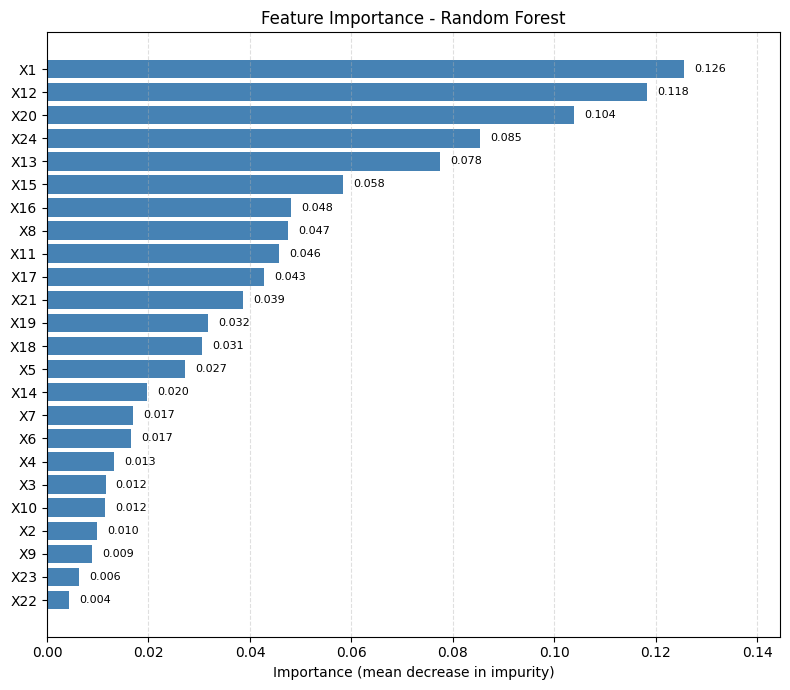

In [58]:
# 07 Visualize feature importance 
importance = pd.DataFrame({
    'feature'   : features,
    'importance': best_rf.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

top_n = 24   
plot_df = importance.head(top_n).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 7))
bars = ax.barh(plot_df['feature'], plot_df['importance'], color='steelblue')

for bar, val in zip(bars, plot_df['importance']):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontsize=8)

ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_title('Feature Importance - Random Forest')
ax.set_xlim(0, plot_df['importance'].max() * 1.15)
ax.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

In [59]:
# 08 Model and metric evaluation.
random_r2 = cross_val_score(
    RandomForestRegressor(**study.best_params, random_state=42, n_jobs=-1),
    X_train, y_train, cv=5, scoring='r2'
)

spatial_r2 = []
for tr_idx, va_idx in inner_splits:
    m = RandomForestRegressor(**study.best_params, random_state=42, n_jobs=-1)
    m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    spatial_r2.append(r2_score(y_train.iloc[va_idx], m.predict(X_train.iloc[va_idx])))

print("\n── Sanity Check ──")
print(f"  Random KFold R²  : {random_r2.mean():.4f} ± {random_r2.std():.4f}")
print(f"  Spatial CV R²    : {np.mean(spatial_r2):.4f} ± {np.std(spatial_r2):.4f}")
print(f"  Gap (inflate)    : {random_r2.mean() - np.mean(spatial_r2):+.4f}")
print("  → Gap > 0.10 = ada spatial leakage di random KFold")


── Sanity Check ──
  Random KFold R²  : 0.6081 ± 0.1054
  Spatial CV R²    : 0.8048 ± 0.0641
  Gap (inflate)    : -0.1966
  → Gap > 0.10 = ada spatial leakage di random KFold


Test R2=0.7627 | RMSE=0.2786 | MAE=0.2209


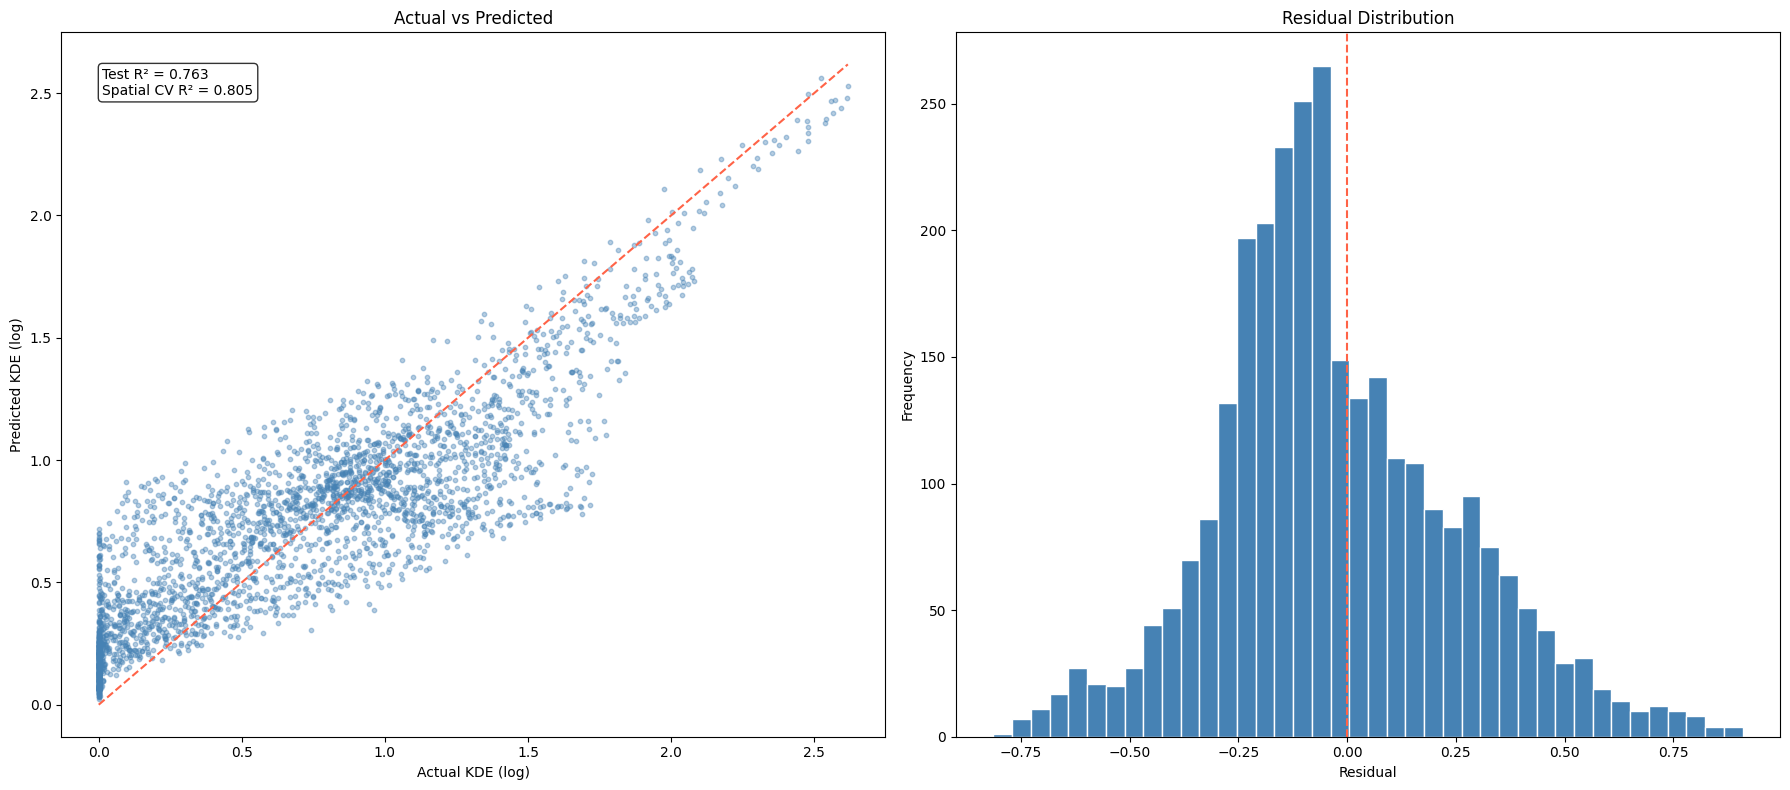

In [60]:
# 09 Regression curve and residual value distribution on test data.
y_pred_log = best_rf.predict(X_test)
residuals  = y_test.values - y_pred_log

r2_test   = r2_score(y_test, y_pred_log)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_log))
mae_test  = mean_absolute_error(y_test, y_pred_log)
print(f"Test R2={r2_test:.4f} | RMSE={rmse_test:.4f} | MAE={mae_test:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

ax = axes[0]
ax.scatter(y_test, y_pred_log, alpha=0.4, s=10, color='steelblue')
lims = [min(y_test.min(), y_pred_log.min()), max(y_test.max(), y_pred_log.max())]
ax.plot(lims, lims, '--', color='tomato')
ax.set_xlabel('Actual KDE (log)')
ax.set_ylabel('Predicted KDE (log)')
ax.set_title('Actual vs Predicted')
ax.text(0.05, 0.95,
    f"Test R² = {r2_test:.3f}\nSpatial CV R² = {np.mean(spatial_r2):.3f}",
    transform=ax.transAxes, va='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax = axes[1]
ax.hist(residuals, bins=40, color='steelblue', edgecolor='white')
ax.axvline(0, linestyle='--', color='tomato')
ax.set_xlabel('Residual')
ax.set_ylabel('Frequency')
ax.set_title('Residual Distribution')

plt.tight_layout()
plt.savefig('rf_regression_diagnostics.png', dpi=300, bbox_inches='tight')
plt.show()

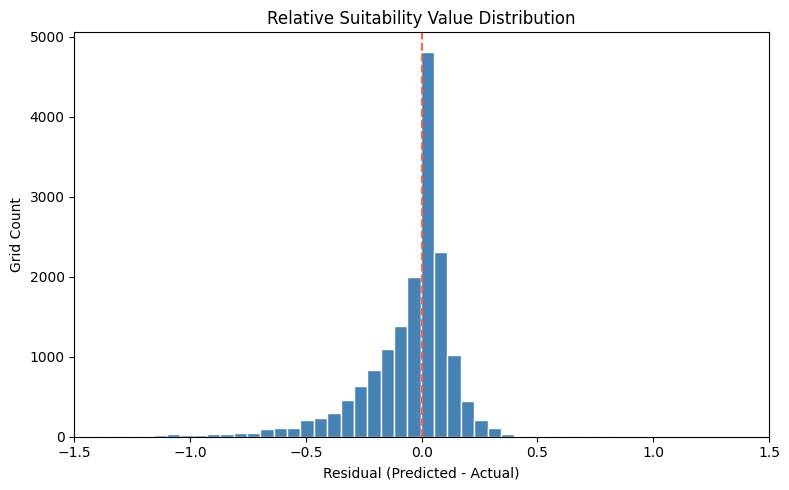

In [61]:
# 10 Model fit and relative suitability value distribution.
rf_final = RandomForestRegressor(**study.best_params, random_state=42, n_jobs=-1)
rf_final.fit(X, y)

gdf['kde_actual']    = np.expm1(y)
gdf['kde_predicted'] = np.expm1(rf_final.predict(X))
gdf['residual_rf']   = gdf['kde_predicted'] - gdf['kde_actual']

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(gdf['residual_rf'], bins=50, color='steelblue', edgecolor='white')
ax.axvline(0, linestyle='--', color='tomato')
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel('Residual (Predicted - Actual)')
ax.set_ylabel('Grid Count')
ax.set_title('Relative Suitability Value Distribution')
plt.tight_layout()
plt.show()

# EXPORT IS OPTIONAL
# gdf.to_file('hasil_residual.gpkg', driver='GPKG')